# 05 · Probability calibration and bookmaker benchmark

**Goal of this notebook:** check how *good* the predicted probabilities of the three models
(Logistic Regression, Random Forest, XGBoost) are, and compare them with the probabilities
implied by Bet365's betting odds.

Nothing is trained or tuned here. The notebook uses the per-match predictions saved by commit 7
(`python -m src.train`):

| Season | Models trained on | Role |
|---|---|---|
| Validation 2025-26 (380 matches) | 1993-94 to 2024-25 | Used in commit 7 to **choose** each model's settings |
| Test 2026-27 (100 completed matches) | 1993-94 to 2025-26 | Never used for any choice |

The two seasons are always reported separately.

**Rules for the bookmaker odds:**
- They are a **benchmark only**, never model features. `src/train.py` accepts only the
  engineered pre-match features.
- Each game's odds are matched to its fixture by date, home team and away team, and the stored
  result must agree.
- There is no betting-profit analysis in this notebook.

The new reusable code is in `src/evaluate.py` (Brier score, reliability tables, calibration
summary, paired bootstrap) and `src/bookmaker.py` (odds to probabilities, coverage, fixture
matching).

## 1. Accuracy is not the same as probability quality

| Question | Metrics | Uses |
|---|---|---|
| **Prediction accuracy:** is the most likely outcome the one that happens? | Accuracy, macro F1 | Only the top pick |
| **Probability quality:** are the probabilities themselves right? | Log loss, Brier score, calibration | All three probabilities |

Two forecasts can pick exactly the same winners and still differ in quality. Say both pick a home
win: one gives it 60% and the other 90%. If home teams in that situation win 60% of the time,
the first forecast is better.

- **Log loss** is `-log(probability given to what happened)`. It punishes confident mistakes very
  hard: 0.69 for a 50% call, 2.3 for a 10% call.
- **Brier score (multiclass)** is the squared distance between the three probabilities and the
  outcome (1 for what happened, 0 otherwise), summed over home win, draw and away win.
  - It runs from 0 (certain and right) to 2 (certain and wrong).
  - Giving 1/3 to every outcome scores 0.667.
  - It is gentler than log loss on confident mistakes.
- **Calibration**: among all matches where a forecast says "40% home win", do about 40% end in a
  home win?

Lower is better for log loss and Brier score.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MultipleLocator, PercentFormatter

from src.bookmaker import (
    BOOKMAKER_LABEL, ODDS_COLUMNS, bookmaker_probabilities, build_benchmark, implied_probabilities,
    odds_coverage, overround,
)
from src.config import FIGURES_DIR
from src.evaluate import (
    OUTCOME_NAMES, OUTCOMES, bootstrap_table, calibration_summary, evaluate, metrics_table,
    per_match_log_loss, reliability_table,
)
from src.feature_engineering import load_features
from src.models import MODEL_SPECS
from src.preprocessing import load_matches
from src.train import (
    BASELINE_LABEL, TEST_SEASON, TRAIN_LAST_SEASON, VALIDATION_SEASON, chronological_split,
    load_predictions, predictions_path, run_experiment, save_artifacts, season_name, target,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

matches = load_matches()
features = load_features()

# The saved predictions are git-ignored. If they are missing, repeat the deterministic commit-7
# run (same grids, same validation season): this recreates them, it does not re-tune anything.
for name in MODEL_SPECS:
    if not all(predictions_path(name, split).exists() for split in ("validation", "test")):
        print(f"Saved predictions for {name} not found: re-running the commit-7 experiment")
        save_artifacts(run_experiment(features, model_name=name))

MODELS = [MODEL_SPECS[name].label for name in MODEL_SPECS]
SPLITS = {"validation": f"Validation {season_name(VALIDATION_SEASON)}",
          "test": f"Test {season_name(TEST_SEASON)}"}
LAST_TRAIN_SEASON = {"validation": TRAIN_LAST_SEASON, "test": VALIDATION_SEASON}
BASELINE = "Baseline"

benchmarks, forecasts = {}, {}
for split in SPLITS:
    saved = {MODEL_SPECS[name].label: load_predictions(name, split) for name in MODEL_SPECS}
    benchmark = build_benchmark(saved, matches)  # matches fixtures and checks the results agree
    # Baseline: the outcome frequencies of the models' own training seasons
    train_rows, _ = chronological_split(features, LAST_TRAIN_SEASON[split], LAST_TRAIN_SEASON[split] + 1)
    prior = target(train_rows).value_counts(normalize=True).reindex(OUTCOMES)
    baseline = pd.DataFrame([prior.to_numpy()] * len(benchmark.fixtures), columns=OUTCOMES,
                            index=benchmark.fixtures.index)
    benchmarks[split] = benchmark
    forecasts[split] = benchmark.probabilities | {BASELINE: baseline}
    print(f"{SPLITS[split]}: {benchmark.total} predicted fixtures, {len(benchmark.fixtures)} with complete "
          f"Bet365 odds ({benchmark.coverage:.0%}), {benchmark.excluded} excluded")

FORECASTS = MODELS + [BOOKMAKER_LABEL]  # the four forecasts compared throughout

Validation 2025-26: 380 predicted fixtures, 380 with complete Bet365 odds (100%), 0 excluded
Test 2026-27: 100 predicted fixtures, 100 with complete Bet365 odds (100%), 0 excluded


In [2]:
# --- Chart style (same as notebooks 01-04) -------------------------------------
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE_LINE = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, YELLOW, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#a3a29b"
# Models keep their notebook-04 colours; the bookmaker takes categorical slot 4
COLORS = {"Logistic Regression": BLUE, "Random Forest": ORANGE, "XGBoost": AQUA,
          BOOKMAKER_LABEL: YELLOW, BASELINE: GRAY}
SHORT = {"Logistic Regression": "LR", "Random Forest": "RF", "XGBoost": "XGB",
         BOOKMAKER_LABEL: "Bookmaker", BASELINE: "Baseline"}


def style_axes(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE_LINE)
    ax.tick_params(colors=MUTED, labelsize=8, length=0)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)


def set_title(ax, title, subtitle=None, size=12):
    ax.set_title(title, loc="left", fontsize=size, color=INK, pad=26 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.015, subtitle, transform=ax.transAxes, fontsize=9, color=INK_2, va="bottom")


def save_figure(fig, name):
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / name, dpi=150, facecolor=SURFACE, bbox_inches="tight")

## 2. The bookmaker benchmark

### 2.1 From odds to probabilities

Football-Data provides Bet365's decimal 1X2 odds (`B365H`, `B365D`, `B365A`). These are
**pre-closing** odds, collected a day or two before kick-off. Odds of 2.00 pay twice the stake,
so the implied probability is `1 / 2.00 = 50%`.

The three implied probabilities of a match add up to slightly more than 100%. That total is the
**overround**, and the excess is the bookmaker's margin. Dividing each implied probability by the
total removes the margin, giving three probabilities that sum to exactly 1.

In [3]:
example = matches[matches["season_start"] == VALIDATION_SEASON].iloc[[0]]
odds = example[[ODDS_COLUMNS[o] for o in OUTCOMES]].to_numpy()[0]
implied = implied_probabilities(example).iloc[0]
fair = bookmaker_probabilities(example).iloc[0]
row = example.iloc[0]
print(f"{row['home_team']} v {row['away_team']}, {row['date']:%d %b %Y} (result: {row['result']})")
pd.DataFrame(
    {"decimal odds": odds, "implied 1/odds": implied.to_numpy(), "margin removed": fair.to_numpy()},
    index=[OUTCOME_NAMES[o] for o in OUTCOMES],
).T.assign(total=lambda t: t.sum(axis=1).where(t.index != "decimal odds")).style.format("{:.3f}", na_rep="")

Genoa v Lecce, 23 Aug 2025 (result: D)


,Home win,Draw,Away win,total
decimal odds,1.900,3.300,4.500,
implied 1/odds,0.526,0.303,0.222,1.052
margin removed,0.501,0.288,0.211,1.000


### 2.2 Coverage and overround

In [4]:
coverage = odds_coverage(matches)
coverage["margin"] = coverage["mean_overround"] - 1
with_odds = coverage[coverage["with_odds"] > 0]
print(f"Seasons without Bet365 odds: {', '.join(coverage.index[coverage['with_odds'] == 0])}")
print(f"From {with_odds.index[0]}: {with_odds['with_odds'].sum():,} of {with_odds['matches'].sum():,} "
      f"completed matches have all three odds ({with_odds['with_odds'].sum() / with_odds['matches'].sum():.1%})")
coverage.tail(6).style.format({"coverage": "{:.0%}", "mean_overround": "{:.4f}", "min_overround": "{:.4f}",
                               "max_overround": "{:.4f}", "margin": "{:.2%}"})

Seasons without Bet365 odds: 1993-94, 1994-95, 1995-96, 1996-97, 1997-98, 1998-99, 1999-00, 2000-01, 2001-02
From 2002-03: 9,027 of 9,072 completed matches have all three odds (99.5%)


,matches,with_odds,coverage,mean_overround,min_overround,max_overround,margin
season,,,,,,,
2021-22,380,379,100%,1.0547,1.0414,1.0763,5.47%
2022-23,380,380,100%,1.0539,1.0367,1.0802,5.39%
2023-24,380,380,100%,1.0539,1.0380,1.0854,5.39%
2024-25,380,380,100%,1.0552,1.0364,1.0741,5.52%
2025-26,380,380,100%,1.0551,1.0381,1.0807,5.51%
2026-27,100,100,100%,1.0546,1.0427,1.0817,5.46%


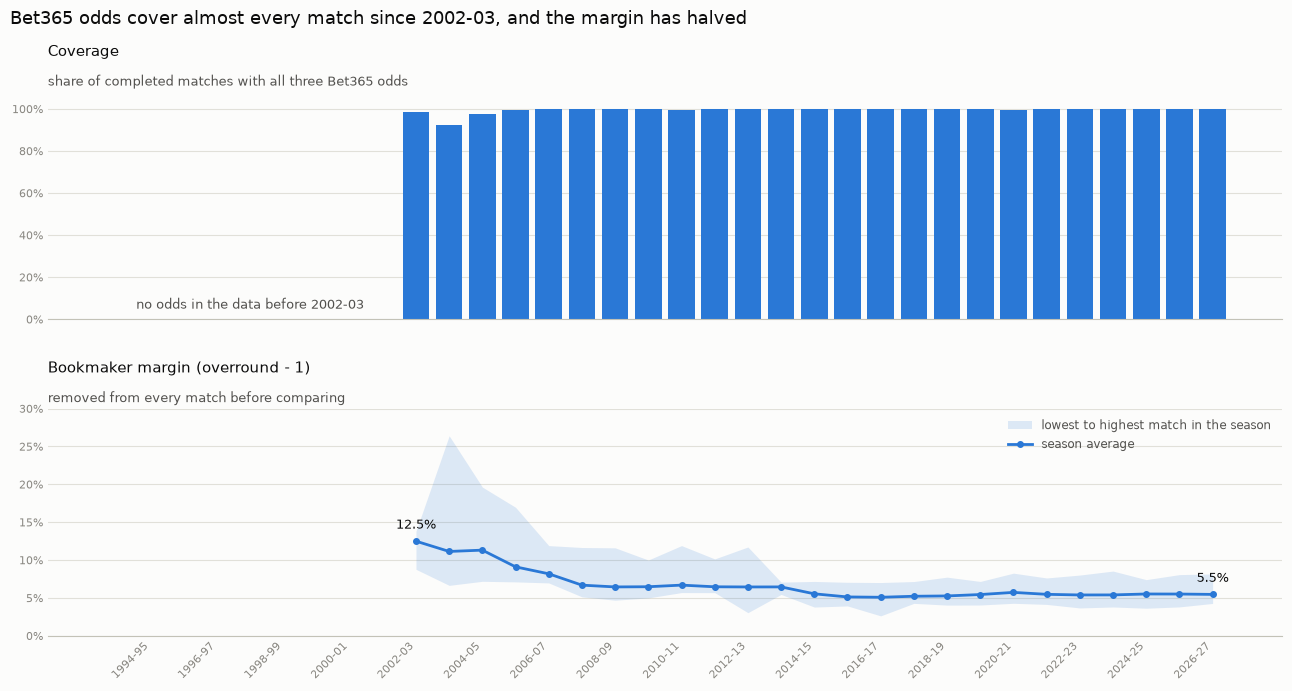

In [5]:
seasons = coverage.index.tolist()
x = np.arange(len(seasons))
fig, axes = plt.subplots(2, 1, figsize=(13, 7), facecolor=SURFACE, sharex=True)

ax = axes[0]
ax.bar(x, coverage["coverage"], width=0.8, color=BLUE)
ax.text(4, 0.05, "no odds in the data before 2002-03", ha="center", fontsize=9, color=INK_2)
ax.set_ylim(0, 1.08)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
style_axes(ax)
set_title(ax, "Coverage", "share of completed matches with all three Bet365 odds", size=11)

ax = axes[1]
ax.fill_between(x, coverage["min_overround"] - 1, coverage["max_overround"] - 1, color=BLUE, alpha=0.15,
                linewidth=0, label="lowest to highest match in the season")
ax.plot(x, coverage["margin"], color=BLUE, linewidth=2, marker="o", markersize=4, label="season average")
for i in (int(np.flatnonzero(coverage["with_odds"] > 0)[0]), len(x) - 1):
    ax.annotate(f"{coverage['margin'].iloc[i]:.1%}", (x[i], coverage["margin"].iloc[i]), xytext=(0, 9),
                textcoords="offset points", ha="center", fontsize=9, color=INK)
ax.set_ylim(0, 0.3)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ticks = x[::-2][::-1]  # every other season, ending with the latest
ax.set_xticks(ticks, [seasons[i] for i in ticks], fontsize=8, rotation=45, ha="right")
ax.legend(frameon=False, fontsize=8.5, labelcolor=INK_2, loc="upper right")
style_axes(ax)
set_title(ax, "Bookmaker margin (overround - 1)", "removed from every match before comparing", size=11)

fig.suptitle("Bet365 odds cover almost every match since 2002-03, and the margin has halved",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(h_pad=2.5)
save_figure(fig, "23_bookmaker_coverage_overround.png")
plt.show()

**Interpretation**

- There are no Bet365 odds before 2002-03. Since then, 99.5% of completed matches have all three
  odds, and **every** match of 2025-26 and 2026-27 does. The comparison below therefore uses all
  380 validation and all 100 test matches; no fixture is dropped.
- Bet365's average margin fell from 12.5% in 2002-03 to about 5–5.5% since 2014-15. In 2025-26
  and 2026-27 it averages 5.5%, so the three implied probabilities add up to about 105.5% before
  normalisation. The margin of individual matches ranges from about 3.8% to 8.2%.

### 2.3 Are the odds attached to the right fixtures?

`build_benchmark` matches every prediction to exactly one fixture (date + home team + away team)
and stops with an error if a fixture is missing, appears twice, or has a different result. Three
more checks on the real data:

In [6]:
checks = []
for split, benchmark in benchmarks.items():
    book = forecasts[split][BOOKMAKER_LABEL]
    actual = benchmark.actual
    swapped = book.rename(columns={"H": "A", "A": "H"})  # deliberately wrong outcome order
    checks.append({
        "season": SPLITS[split],
        "fixtures matched": len(benchmark.fixtures),
        "results agree": True,  # build_benchmark raises otherwise
        "favourite won": (book.idxmax(axis=1) == actual).mean(),
        "log loss, H/D/A order": evaluate(actual, book)["log_loss"],
        "log loss if H and A were swapped": evaluate(actual, swapped)["log_loss"],
        "corr. with LR home-win prob.": book["H"].corr(forecasts[split]["Logistic Regression"]["H"]),
    })
pd.DataFrame(checks).set_index("season").style.format(
    {"favourite won": "{:.1%}", "log loss, H/D/A order": "{:.3f}", "log loss if H and A were swapped": "{:.3f}",
     "corr. with LR home-win prob.": "{:.2f}"})

,fixtures matched,results agree,favourite won,"log loss, H/D/A order",log loss if H and A were swapped,corr. with LR home-win prob.
season,,,,,,
Validation 2025-26,380,True,53.9%,0.982,1.410,0.93
Test 2026-27,100,True,63.0%,0.898,1.441,0.91


- The bookmaker's favourite wins about as often as the models' pick does (section 3).
- If the home and away columns were mixed up, log loss would rise far above the 1.10 of the
  no-information baseline.
- Bookmaker and model probabilities are strongly correlated, as expected if both describe the
  same games.

Together these confirm that the odds are attached to the right games, in the right outcome order.

## 3. Models and bookmaker on the same fixtures

In [7]:
fmt = {"matches": "{:.0f}", "accuracy": "{:.1%}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}", "brier": "{:.3f}",
       "accuracy_H": "{:.1%}", "accuracy_D": "{:.1%}", "accuracy_A": "{:.1%}"}
scores = {}
for split in SPLITS:
    actual = benchmarks[split].actual
    scores[split] = metrics_table({name: evaluate(actual, forecasts[split][name]) for name in FORECASTS + [BASELINE]})
    display(scores[split].style.format(fmt).set_caption(SPLITS[split]))

,matches,accuracy,macro_f1,log_loss,brier,accuracy_H,accuracy_D,accuracy_A
Logistic Regression,380,51.8%,0.413,1.002,0.599,79.1%,3.0%,57.9%
Random Forest,380,52.9%,0.430,1.003,0.601,82.4%,5.1%,55.6%
XGBoost,380,51.6%,0.426,1.005,0.602,79.1%,6.1%,54.9%
Bookmaker (Bet365),380,53.9%,0.418,0.982,0.584,81.8%,1.0%,62.4%
Baseline,380,38.9%,0.187,1.102,0.669,100.0%,0.0%,0.0%


,matches,accuracy,macro_f1,log_loss,brier,accuracy_H,accuracy_D,accuracy_A
Logistic Regression,100,60.0%,0.460,0.882,0.508,80.9%,6.2%,56.8%
Random Forest,100,63.0%,0.506,0.895,0.518,87.2%,12.5%,54.1%
XGBoost,100,61.0%,0.467,0.882,0.508,83.0%,6.2%,56.8%
Bookmaker (Bet365),100,63.0%,0.452,0.898,0.520,80.9%,0.0%,67.6%
Baseline,100,47.0%,0.213,1.060,0.640,100.0%,0.0%,0.0%


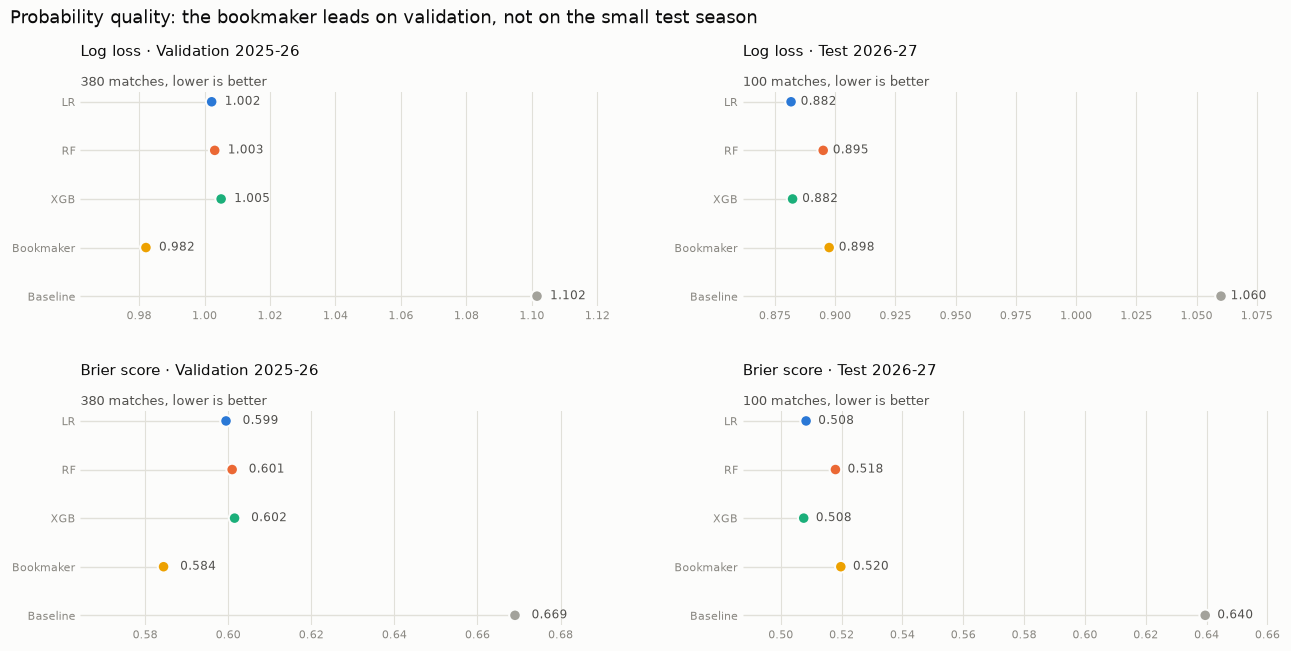

In [8]:
ORDER = FORECASTS + [BASELINE]
panels = [("log_loss", "Log loss"), ("brier", "Brier score")]
fig, axes = plt.subplots(2, 2, figsize=(13, 6.6), facecolor=SURFACE)
for col, split in enumerate(SPLITS):
    for row, (metric, title) in enumerate(panels):
        ax = axes[row, col]
        values = scores[split].loc[ORDER, metric]
        y = np.arange(len(ORDER))[::-1]
        ax.hlines(y, values.min() - 0.02, values, color=GRID, linewidth=1, zorder=1)
        ax.scatter(values, y, s=70, color=[COLORS[n] for n in ORDER], edgecolors=SURFACE, linewidths=1.5, zorder=3)
        for yi, v in zip(y, values):
            ax.text(v + 0.004, yi, f"{v:.3f}", va="center", fontsize=8.5, color=INK_2)
        ax.set_yticks(y, [SHORT[n] for n in ORDER], fontsize=9, color=INK_2)
        ax.set_xlim(values.min() - 0.02, values.max() + 0.025)
        style_axes(ax, grid="x")
        ax.spines["bottom"].set_visible(False)
        set_title(ax, f"{title} · {SPLITS[split]}", f"{len(benchmarks[split].fixtures)} matches, lower is better",
                  size=11)
fig.suptitle("Probability quality: the bookmaker leads on validation, not on the small test season",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(h_pad=3, w_pad=4)
save_figure(fig, "24_probability_scores.png")
plt.show()

**Interpretation**

The models' rows match commit 7 exactly, which confirms that the saved predictions were reused
unchanged.

**Validation 2025-26 (380 matches):**
- The bookmaker has the best log loss (0.982, against 1.002–1.005 for the models) and the best
  Brier score (0.584, against 0.599–0.602).
- It is also the most accurate (53.9%, against 51.6–52.9%).

**Test 2026-27 (100 matches):** the order reverses on probability quality.
- Logistic Regression and XGBoost have a lower log loss (0.882) than the bookmaker (0.898).
- Yet the bookmaker ties Random Forest for the **highest accuracy** (63%).

This is the accuracy versus probability-quality distinction in action. The bookmaker picked the
winner as often as the best model, but its probabilities were less well matched to the outcomes
of these 100 games.

The gap between the models and the bookmaker (about 0.02 log loss on validation) is small
compared with the gap between the models and the baseline (about 0.10). Section 5 tests whether
it is larger than chance.

## 4. Calibration: home win, draw and away win separately

### 4.1 Calibration in the large

First the simplest check: over a whole season, does each forecast expect as many home wins,
draws and away wins as actually happened?

In [9]:
in_the_large = pd.concat({
    SPLITS[split]: pd.concat({
        SHORT[name]: calibration_summary(benchmarks[split].actual, forecasts[split][name])[["mean_predicted", "observed", "difference"]]
        for name in FORECASTS
    }, names=["forecast"])
    for split in SPLITS
}, names=["season"])
in_the_large.unstack("outcome").swaplevel(axis=1)[OUTCOMES].style.format("{:+.1%}", subset=pd.IndexSlice[:, pd.IndexSlice[:, "difference"]]).format(
    "{:.1%}", subset=pd.IndexSlice[:, pd.IndexSlice[:, ["mean_predicted", "observed"]]])

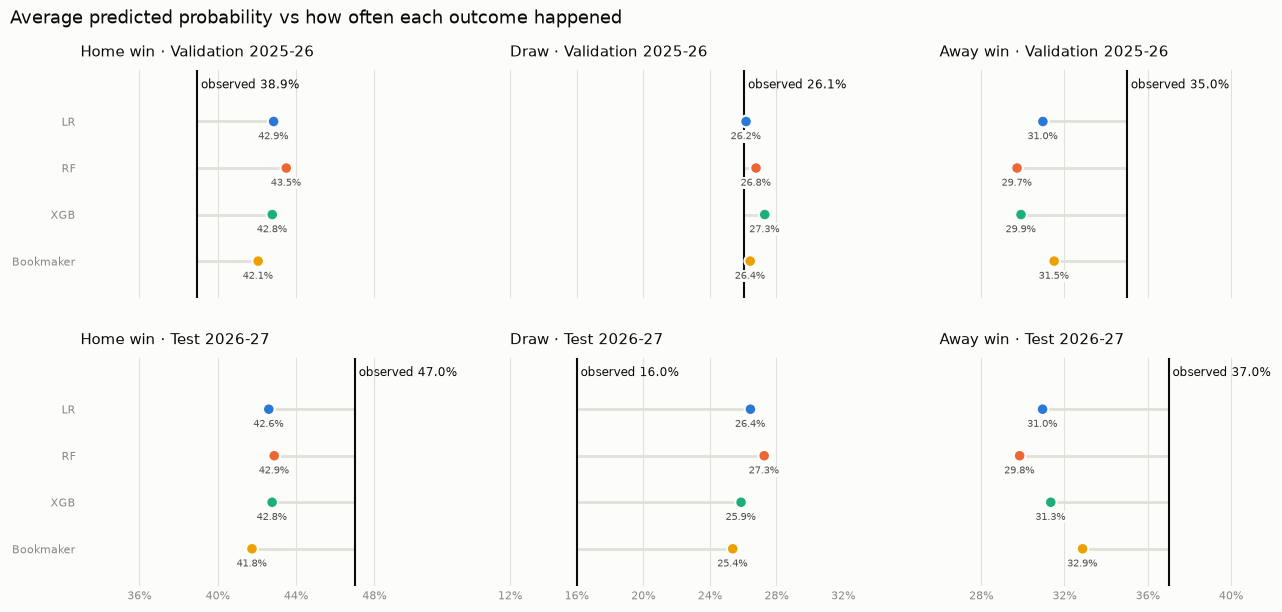

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.2), facecolor=SURFACE, sharex="col")
for row, split in enumerate(SPLITS):
    actual = benchmarks[split].actual
    for col, outcome in enumerate(OUTCOMES):
        ax = axes[row, col]
        observed = (actual == outcome).mean()
        y = np.arange(len(FORECASTS))[::-1]
        means = [forecasts[split][name][outcome].mean() for name in FORECASTS]
        ax.axvline(observed, color=INK, linewidth=1.5, zorder=2)
        ax.text(observed, len(FORECASTS) - 0.35, f" observed {observed:.1%}", fontsize=8.5, color=INK, va="bottom")
        ax.hlines(y, observed, means, color=GRID, linewidth=2, zorder=1)
        ax.scatter(means, y, s=70, color=[COLORS[n] for n in FORECASTS], edgecolors=SURFACE, linewidths=1.5, zorder=3)
        for yi, m in zip(y, means):
            ax.text(m, yi - 0.38, f"{m:.1%}", ha="center", fontsize=7.5, color=INK_2, zorder=4,
                    bbox={"facecolor": SURFACE, "edgecolor": "none", "pad": 0.6})
        ax.set_yticks(y, [SHORT[n] for n in FORECASTS] if col == 0 else [], fontsize=9, color=INK_2)
        ax.set_ylim(-0.8, len(FORECASTS) + 0.1)
        ax.xaxis.set_major_locator(MultipleLocator(0.04))
        ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
        style_axes(ax, grid="x")
        ax.spines["bottom"].set_visible(False)
        set_title(ax, f"{OUTCOME_NAMES[outcome]} · {SPLITS[split]}", None, size=10.5)
axes[0, 0].set_xlim(0.33, 0.50); axes[0, 1].set_xlim(0.12, 0.32); axes[0, 2].set_xlim(0.26, 0.42)
fig.suptitle("Average predicted probability vs how often each outcome happened",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(h_pad=2.5, w_pad=2.5)
save_figure(fig, "25_calibration_in_the_large.png")
plt.show()

**Interpretation**

- **Validation 2025-26:** every forecast, the bookmaker included, expected too many home wins
  (by 3–5 points) and too few away wins (by 3.5–5.5 points). Home teams won only 38.9% of matches
  that season, against 42.4% on average since 2015-16 and 45.4% since 1993-94. The draw share was
  predicted almost exactly.
- **Test 2026-27:** so far, home wins are above average (47%) and draws are rare (16%). Every
  forecast expected about 25–27% draws, so all are about 10 points too high on draws.
- The models and the bookmaker miss in the **same direction** in both seasons. These are
  season-level swings that nobody predicted, not a flaw specific to the models.

### 4.2 Reliability diagrams

A reliability diagram sorts the matches by predicted probability of one outcome, puts them in
bins, and plots the average predicted probability against how often the outcome actually
happened. A well-calibrated forecast lies on the diagonal.

- Points **below** the diagonal: the forecast was too confident.
- Points **above** it: the forecast was too cautious.

The bins hold equal numbers of matches (quantile bins): 8 bins of 47–48 matches on validation and
4 bins of 25 on test. The shaded band is a 95% Wilson interval for the observed frequency, which
shows how much a bin can move by chance alone.

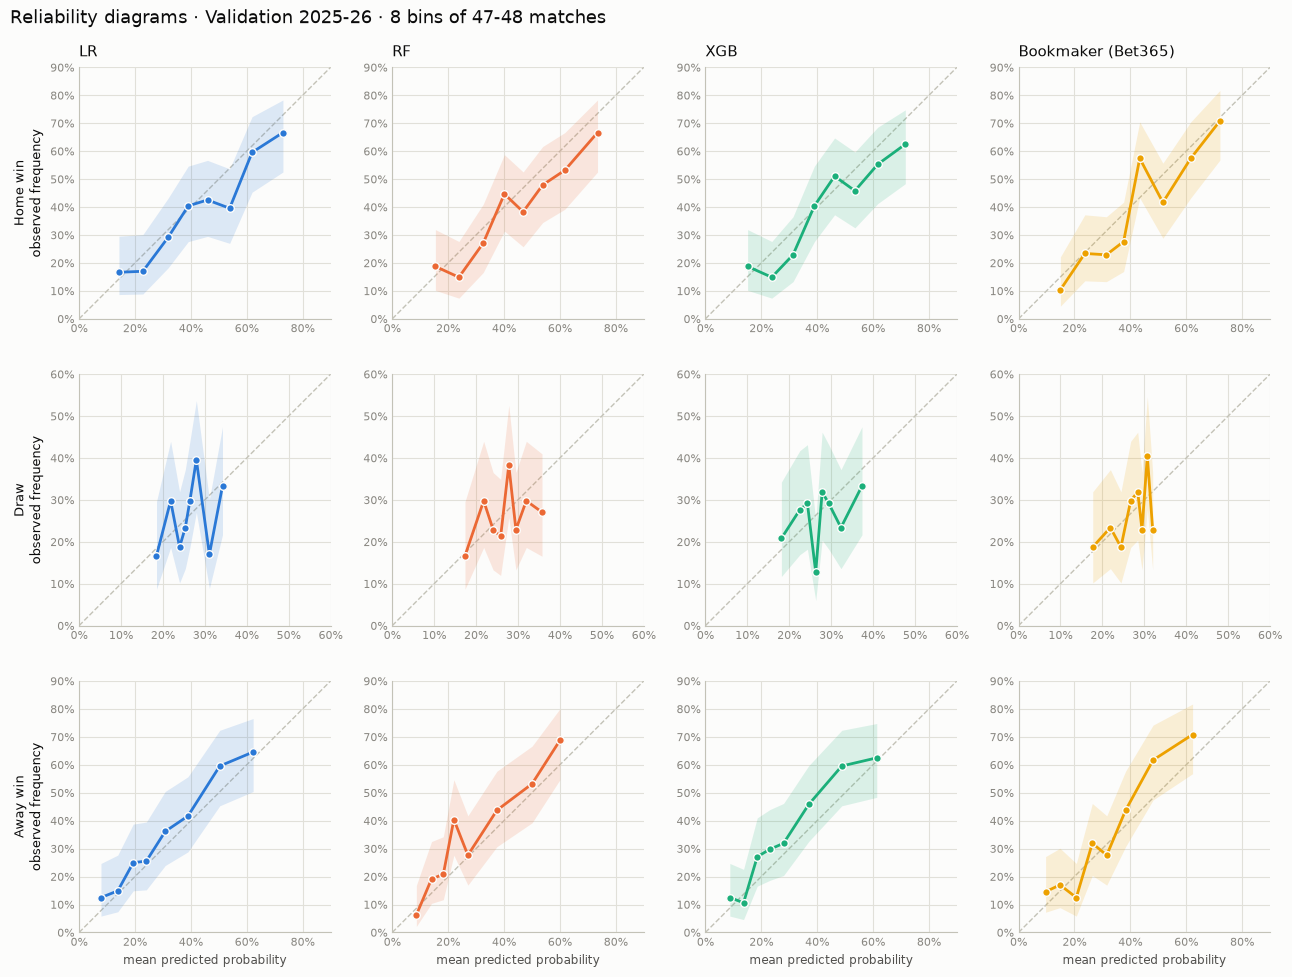

In [11]:
BINS = {"validation": 8, "test": 4}


def reliability_grid(split, filename, title):
    actual = benchmarks[split].actual
    fig, axes = plt.subplots(3, 4, figsize=(13, 10), facecolor=SURFACE)
    for row, outcome in enumerate(OUTCOMES):
        tables = {name: reliability_table(actual, forecasts[split][name], outcome, n_bins=BINS[split])
                  for name in FORECASTS}
        limit = max(max(t["highest"].max(), t["ci_high"].max()) for t in tables.values())
        limit = min(1.0, np.ceil(limit * 10) / 10)
        for col, name in enumerate(FORECASTS):
            ax, t = axes[row, col], tables[name]
            ax.plot([0, limit], [0, limit], color=BASELINE_LINE, linewidth=1, linestyle="--", zorder=1)
            ax.fill_between(t["mean_predicted"], t["ci_low"], t["ci_high"], color=COLORS[name], alpha=0.15,
                            linewidth=0, zorder=2)
            ax.plot(t["mean_predicted"], t["observed"], color=COLORS[name], linewidth=2, marker="o", markersize=5.5,
                    markeredgecolor=SURFACE, markeredgewidth=1, zorder=3)
            ax.set_xlim(0, limit)
            ax.set_ylim(0, limit)
            ax.set_aspect("equal")
            ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
            ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
            style_axes(ax, grid="both")
            ax.spines["left"].set_visible(True)
            ax.spines["left"].set_color(BASELINE_LINE)
            if row == 0:
                ax.set_title(SHORT[name] if name != BOOKMAKER_LABEL else "Bookmaker (Bet365)", loc="left",
                             fontsize=11, color=INK, pad=8)
            if col == 0:
                ax.set_ylabel(f"{OUTCOME_NAMES[outcome]}\nobserved frequency", fontsize=9.5, color=INK)
            if row == 2:
                ax.set_xlabel("mean predicted probability", fontsize=8.5, color=INK_2)
    fig.suptitle(title, x=0.01, ha="left", fontsize=13, color=INK)
    fig.tight_layout(h_pad=1.5, w_pad=1.5)
    save_figure(fig, filename)
    plt.show()


reliability_grid("validation", "26_reliability_validation.png",
                 f"Reliability diagrams · {SPLITS['validation']} · 8 bins of 47-48 matches")

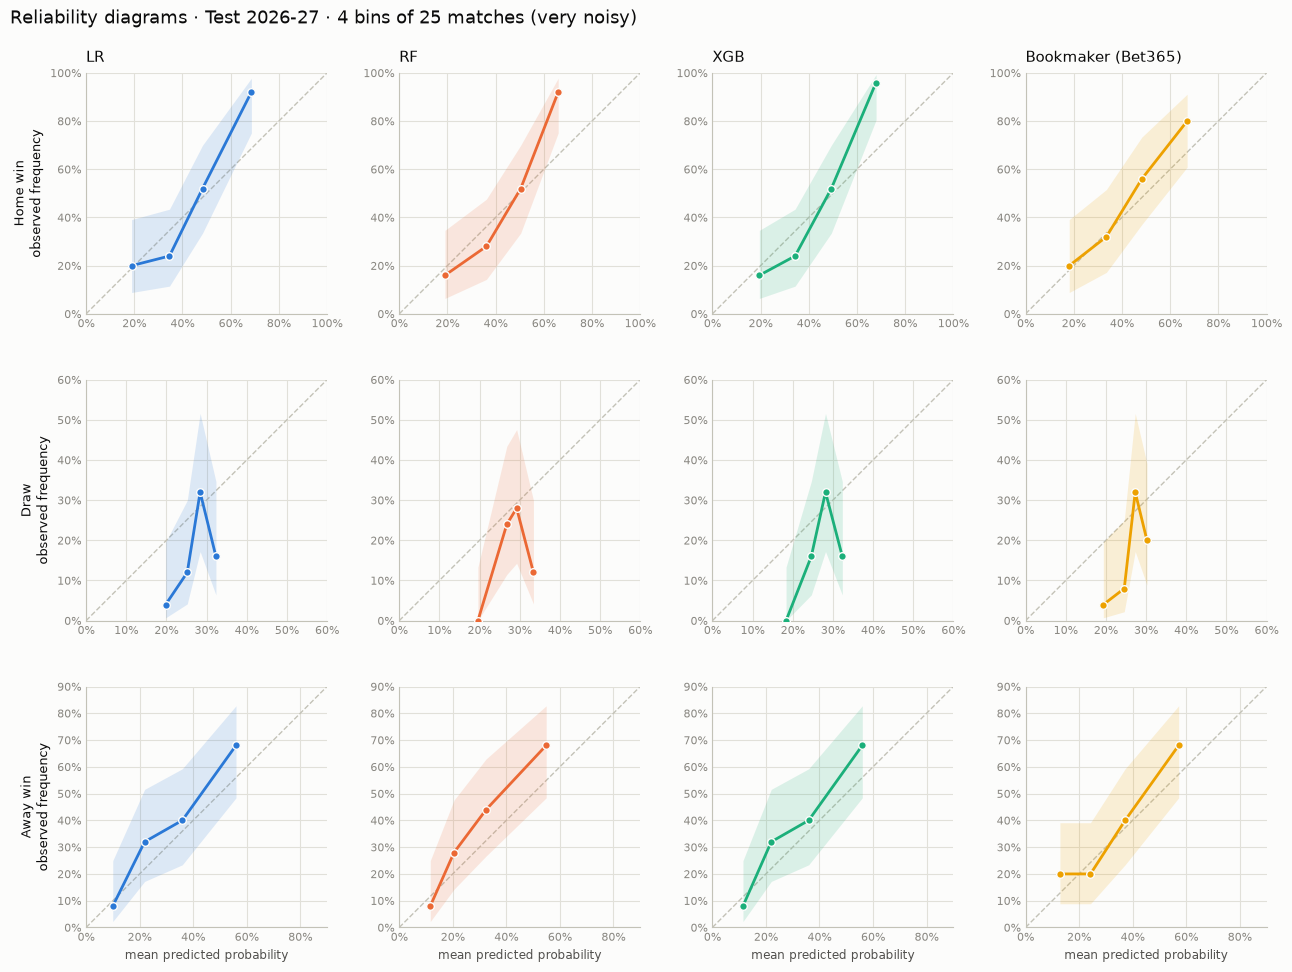

In [12]:
reliability_grid("test", "27_reliability_test.png",
                 f"Reliability diagrams · {SPLITS['test']} · 4 bins of 25 matches (very noisy)")

In [13]:
ece = pd.concat({
    SPLITS[split]: pd.DataFrame({
        SHORT[name]: calibration_summary(benchmarks[split].actual, forecasts[split][name], n_bins=BINS[split])["ece"]
        for name in FORECASTS
    }).T
    for split in SPLITS
}, names=["season", "forecast"]).rename(columns=OUTCOME_NAMES)
print("Expected calibration error: match-weighted average gap between the line and the diagonal")
ece.style.format("{:.3f}").background_gradient(cmap="Blues", axis=None, vmin=0, vmax=0.2)

Expected calibration error: match-weighted average gap between the line and the diagonal


**Interpretation**

**Validation 2025-26:** all four forecasts follow the diagonal for all three outcomes, and almost
every point lies within its 95% band. The probabilities are **reasonably calibrated**, including
the draw probabilities. Within that:

- **Home win:** the models are slightly **over-confident about strong home favourites**.
  - In the top bin, LR and RF predicted about 73% and 66% of those matches were home wins; XGB
    predicted 72% and 62% were.
  - The bookmaker's top bin is on the diagonal (72% predicted, 71% observed).
  - In the middle bins (40–55%), all four sit below the diagonal: the low home-win share of
    2025-26 from 4.1.
- **Away win:** most points lie *above* the diagonal for all four forecasts. More away wins
  happened than predicted, the same season-wide effect.
- **Draw:** predictions are squeezed into a narrow range (bin averages from about 17% to 37%),
  and the observed frequencies zig-zag around the diagonal within their bands.
  - No forecast, the bookmaker included, can identify matches that are very likely to be draws.
  - That is why accuracy on draws is close to zero everywhere.
- **Expected calibration error:**
  - On validation, LR has the lowest ECE for home and away wins and the bookmaker the lowest for
    draws.
  - With 47 matches per bin, chance alone moves a bin by several points, so these ECE
    differences are within the noise. No forecast is clearly better calibrated.

**Test 2026-27:** bins of 25 matches have bands about ±20 points wide.
- Two features stand out: the draw shortfall from 4.1, and strong home favourites winning almost
  every game so far (92–96% in the models' top bin, 80% in the bookmaker's).
- Both are within the bands. 100 matches are too few to judge calibration.

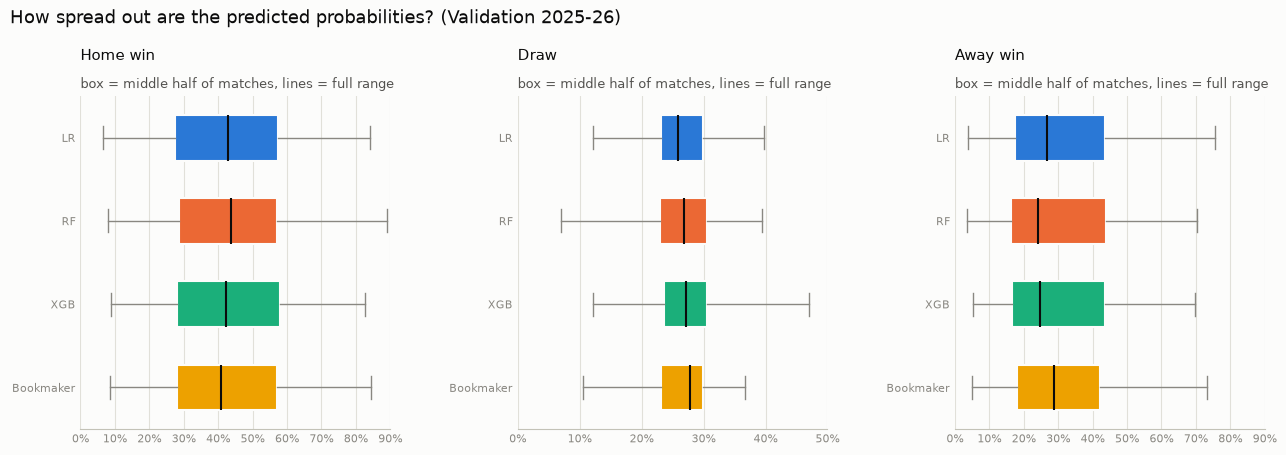

,Home win range,Draw range,Away win range,Home win st. dev.,Draw st. dev.,Away win st. dev.
LR,6%-84%,12%-40%,4%-76%,0.188,0.048,0.177
RF,8%-89%,7%-39%,4%-70%,0.185,0.056,0.171
XGB,9%-83%,12%-47%,5%-70%,0.183,0.058,0.172
Bookmaker,9%-84%,11%-37%,5%-73%,0.182,0.046,0.167


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), facecolor=SURFACE)
val = forecasts["validation"]
for ax, outcome in zip(axes, OUTCOMES):
    data = [val[name][outcome] for name in FORECASTS]
    parts = ax.boxplot(data, orientation="horizontal", widths=0.55, patch_artist=True, whis=(0, 100),
                       medianprops={"color": INK, "linewidth": 1.5},
                       whiskerprops={"color": MUTED}, capprops={"color": MUTED})
    for box, name in zip(parts["boxes"], FORECASTS):
        box.set_facecolor(COLORS[name])
        box.set_edgecolor(SURFACE)
        box.set_linewidth(1.5)
    ax.set_yticks(range(1, len(FORECASTS) + 1), [SHORT[n] for n in FORECASTS], fontsize=9, color=INK_2)
    ax.invert_yaxis()
    ax.set_xlim(0, 0.9 if outcome != "D" else 0.5)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    style_axes(ax, grid="x")
    set_title(ax, OUTCOME_NAMES[outcome], "box = middle half of matches, lines = full range", size=11)
fig.suptitle(f"How spread out are the predicted probabilities? ({SPLITS['validation']})",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(w_pad=3)
save_figure(fig, "28_probability_spread.png")
plt.show()

spread = pd.DataFrame({SHORT[n]: {f"{OUTCOME_NAMES[o]} range": f"{val[n][o].min():.0%}-{val[n][o].max():.0%}"
                                  for o in OUTCOMES} | {f"{OUTCOME_NAMES[o]} st. dev.": val[n][o].std() for o in OUTCOMES}
                       for n in FORECASTS}).T
spread.style.format("{:.3f}", subset=[c for c in spread.columns if "st. dev." in c])

**Interpretation:** calibration alone is not enough. A forecast that always predicted the
long-run frequencies would be perfectly calibrated "in the large", yet useless. Good forecasts
must also **separate** the matches, which is called sharpness or resolution.

- **The spreads are almost identical.** The home-win standard deviation is 0.182–0.188 for all
  four forecasts, and the ranges are similar (about 6–9% up to 83–89%).
  - The bookmaker is **not** bolder than the models.
  - Its edge on validation comes from putting the same spread on the *right* matches: it ranks
    favourites and underdogs better.
  - That shows up as higher accuracy (53.9%) and a better-calibrated top home-win bin (4.2).
- **Draws:** the bookmaker's draw probabilities are the most compressed (11–37%, st. dev. 0.046).
  - Random Forest reaches lowest (7%) and XGBoost highest (47%), but most matches still sit
    between about 23% and 31% for every forecast.

## 5. Are the differences larger than chance?

The log loss of one season is just one sample, and a different set of 380 matches would give
different numbers. A **paired bootstrap** estimates how much the *difference* between two
forecasts could move by chance:

1. Score both forecasts on every match.
2. Resample the 380 (or 100) matches with replacement 10,000 times, keeping each match's pair of
   scores together.
3. Recompute the difference in mean log loss each time. The middle 95% of those differences is
   the confidence interval.

A negative difference means the first forecast (A) is better. If the interval includes 0, this
sample cannot tell the two forecasts apart.

In [15]:
PAIRS = [(m, BOOKMAKER_LABEL) for m in MODELS] + [
    ("Logistic Regression", "Random Forest"), ("Logistic Regression", "XGBoost"), ("Random Forest", "XGBoost")]
bootstrap = {}
for metric in ("log_loss", "brier"):
    for split in SPLITS:
        table = bootstrap_table(benchmarks[split].actual, forecasts[split], PAIRS, metric=metric)
        table.insert(0, "season", SPLITS[split])
        bootstrap[(metric, split)] = table


def show(metric):
    table = pd.concat([bootstrap[(metric, s)] for s in SPLITS], ignore_index=True)
    table["a"] = table["a"].map(SHORT)
    table["b"] = table["b"].map(SHORT)
    return (table.drop(columns=["metric"]).set_index(["season", "a", "b"]).style
            .format({"difference": "{:+.4f}", "ci_low": "{:+.4f}", "ci_high": "{:+.4f}", "share_a_better": "{:.0%}"})
            .set_caption(f"Paired bootstrap, difference in {metric.replace('_', ' ')} (A - B), 10,000 resamples"))


show("log_loss")

In [16]:
show("brier")

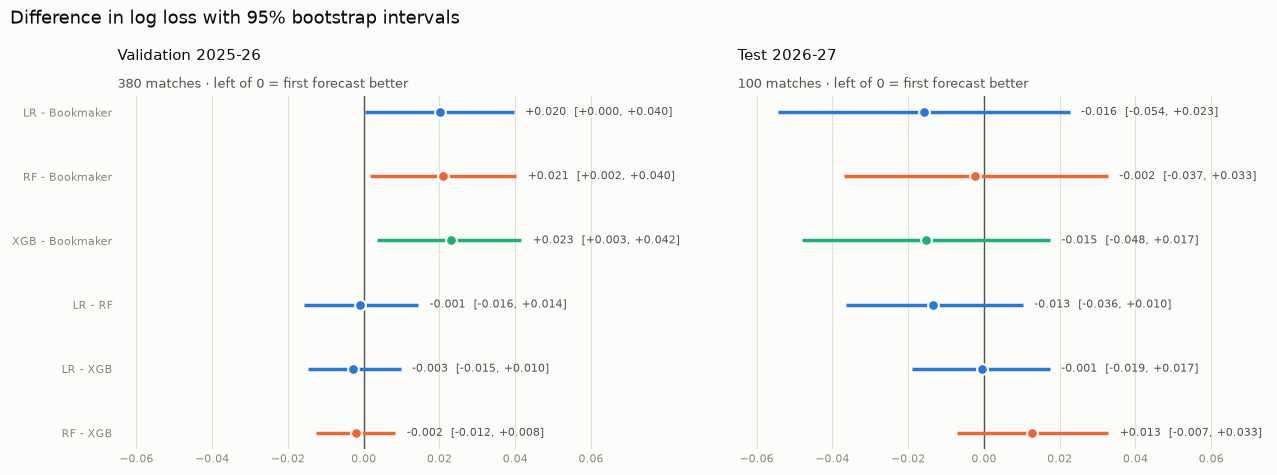

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), facecolor=SURFACE, sharey=True)
for ax, split in zip(axes, SPLITS):
    table = bootstrap[("log_loss", split)]
    y = np.arange(len(table))[::-1]
    ax.axvline(0, color=INK_2, linewidth=1, zorder=1)
    for yi, (_, r) in zip(y, table.iterrows()):
        color = COLORS[r["a"]]
        ax.hlines(yi, r["ci_low"], r["ci_high"], color=color, linewidth=2.5, zorder=2)
        ax.scatter(r["difference"], yi, s=60, color=color, edgecolors=SURFACE, linewidths=1.5, zorder=3)
        ax.text(r["ci_high"] + 0.003, yi, f"{r['difference']:+.3f}  [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]",
                va="center", fontsize=8, color=INK_2)
    labels = [f"{SHORT[a]} - {SHORT[b]}" for a, b in zip(table["a"], table["b"])]
    ax.set_yticks(y, labels, fontsize=9, color=INK_2)
    ax.set_xlim(-0.065, 0.075)
    style_axes(ax, grid="x")
    ax.spines["bottom"].set_visible(False)
    set_title(ax, SPLITS[split], f"{len(benchmarks[split].fixtures)} matches · left of 0 = first forecast better",
              size=11)
fig.suptitle("Difference in log loss with 95% bootstrap intervals", x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(w_pad=3)
save_figure(fig, "29_bootstrap_log_loss.png")
plt.show()

**Interpretation**

**Validation 2025-26:**
- Each model's log loss is about 0.02 higher than the bookmaker's.
- For all three models, the 95% interval lies just above 0, with lower ends between +0.000 and
  +0.004. The Brier score gives the same picture.
- On this season, the bookmaker's probabilities were **better than every model's by more than
  this bootstrap attributes to chance**, but only narrowly.

**Test 2026-27:**
- The models' lower log loss comes with intervals of about ±0.035, which easily include 0.
- 100 matches cannot tell the models and the bookmaker apart.

**Between the models:** every interval includes 0 on both seasons, which confirms the commit-7
conclusion that none of the three models is better than the others.

**How far to trust these intervals:**
- **Not a formal significance test.** Six comparisons are made per season, with no correction
  for multiple comparisons. An interval that only just excludes 0 should be read as "probably a
  real but small gap", not as proof.
- **Independence assumption.** The bootstrap treats matches as independent. Games on the same
  weekend or with the same teams share information, so the true uncertainty is somewhat larger
  than shown.
- **One season each.** The validation and test seasons are one sample each, and 2025-26 had an
  unusually low share of home wins. Other seasons could rank the forecasts differently.
- **Validation favours the models.** The models' settings were chosen on 2025-26, so their
  validation scores are, if anything, slightly optimistic. The bookmaker was not tuned on it.
- **Small test sample.** With 100 matches, the test intervals are wide. They will narrow as the
  2026-27 season is completed.

## 6. Where do models and bookmaker disagree?

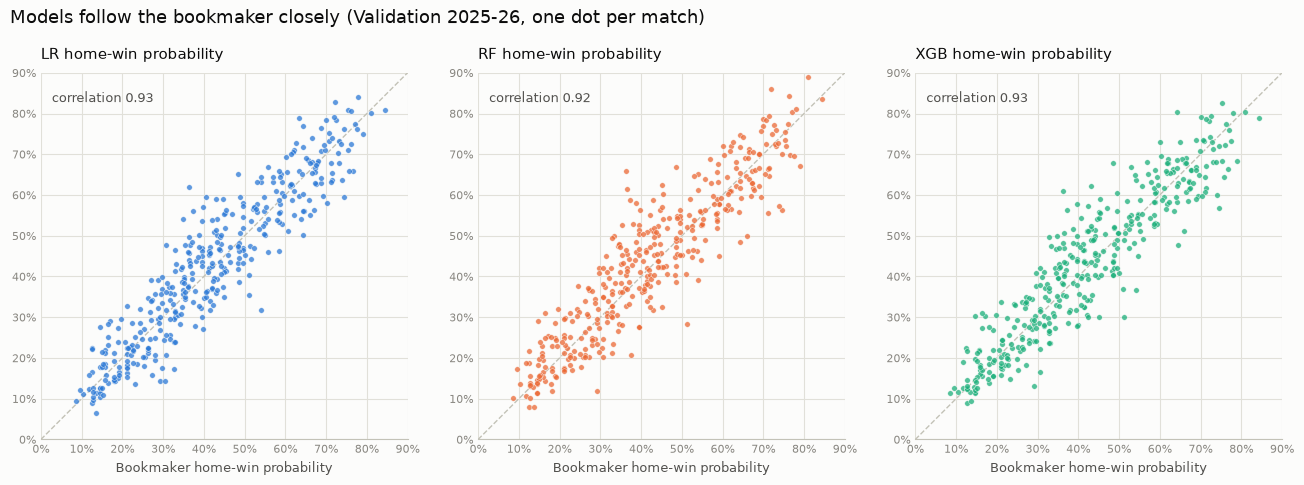

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), facecolor=SURFACE)
book = val[BOOKMAKER_LABEL]["H"]
for ax, name in zip(axes, MODELS):
    ax.plot([0, 0.9], [0, 0.9], color=BASELINE_LINE, linewidth=1, linestyle="--", zorder=1)
    ax.scatter(book, val[name]["H"], s=16, color=COLORS[name], alpha=0.75, edgecolors=SURFACE, linewidths=0.4,
               zorder=2)
    ax.text(0.03, 0.95, f"correlation {book.corr(val[name]['H']):.2f}", transform=ax.transAxes, fontsize=9,
            color=INK_2, va="top")
    ax.set_xlim(0, 0.9)
    ax.set_ylim(0, 0.9)
    ax.set_aspect("equal")
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel("Bookmaker home-win probability", fontsize=9, color=INK_2)
    style_axes(ax, grid="both")
    set_title(ax, f"{SHORT[name]} home-win probability", None, size=11)
fig.suptitle(f"Models follow the bookmaker closely ({SPLITS['validation']}, one dot per match)",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(w_pad=3)
save_figure(fig, "30_models_vs_bookmaker.png")
plt.show()

In [19]:
fixtures = benchmarks["validation"].fixtures
gap = val["Logistic Regression"]["H"] - book
largest = gap.abs().sort_values(ascending=False).index[:8]
disagreements = fixtures.loc[largest, ["date", "home_team", "away_team", "actual"]].assign(
    LR_home_win=val["Logistic Regression"].loc[largest, "H"],
    bookmaker_home_win=book.loc[largest],
    difference=gap.loc[largest],
    LR_log_loss=per_match_log_loss(fixtures["actual"], val["Logistic Regression"]).loc[largest],
    bookmaker_log_loss=per_match_log_loss(fixtures["actual"], val[BOOKMAKER_LABEL]).loc[largest],
)
print(f"Average absolute gap in home-win probability (LR vs bookmaker): {gap.abs().mean():.1%}")
disagreements.style.format({"date": "{:%d %b %Y}", "LR_home_win": "{:.0%}", "bookmaker_home_win": "{:.0%}",
                            "difference": "{:+.0%}", "LR_log_loss": "{:.2f}", "bookmaker_log_loss": "{:.2f}"})

Average absolute gap in home-win probability (LR vs bookmaker): 5.5%


,date,home_team,away_team,actual,LR_home_win,bookmaker_home_win,difference,LR_log_loss,bookmaker_log_loss
10,29 Aug 2025,Cremonese,Sassuolo,H,62%,36%,+26%,0.48,1.01
374,24 May 2026,Lecce,Genoa,H,32%,54%,-22%,1.14,0.62
368,17 May 2026,Sassuolo,Lecce,A,54%,35%,+19%,1.77,1.03
369,17 May 2026,Udinese,Cremonese,A,60%,41%,+19%,1.96,1.17
34,21 Sep 2025,Cremonese,Parma,D,56%,37%,+19%,1.37,1.21
136,07 Dec 2025,Napoli,Juventus,H,57%,40%,+17%,0.56,0.92
311,11 Apr 2026,Atalanta,Juventus,A,48%,31%,+17%,1.27,0.90
91,01 Nov 2025,Napoli,Como,D,65%,48%,+17%,1.45,1.19


**Interpretation**

- The models' home-win probabilities track the bookmaker's closely (correlation of about 0.92–0.93).
  The models, built only on past results, recover most of what the betting market knows about
  team strength.
- On average, LR's home-win probability differs from the bookmaker's by 5.5 points.
- The eight largest disagreements (15–26 points) show where past results are a weak guide:
  - **Promoted teams:** Cremonese, Sassuolo and Pisa came up in 2025-26. Cremonese appears in
    three of the eight matches and Sassuolo in two. The models have no last-season Serie A data
    for them; the bookmaker knows about their squads and transfers.
  - **The last two rounds** (17 and 24 May 2026), when motivation and squad rotation matter and
    the odds can reflect them.
  - **Big games** such as Napoli v Juventus.
- In six of the eight, the bookmaker's probability was closer to what happened (lower per-match
  log loss). A few examples are not evidence on their own, but they fit the gap in section 5: the
  bookmaker has information the models do not.

## Key findings

| Finding | Detail |
|---|---|
| Accuracy ≠ probability quality | On test, the bookmaker ties for the highest accuracy (63%) but has a worse log loss than LR and XGBoost |
| The bookmaker is better on validation | Log loss 0.982 vs 1.002–1.005; the bootstrap intervals lie narrowly above 0 for all three models |
| The test season cannot separate them | The models score slightly better, but the ±0.035 intervals easily include 0 |
| The models are reasonably calibrated | Reliability curves stay mostly within their 95% bands. The main misses are season-wide (fewer home wins in 2025-26, fewer draws so far in 2026-27) and shared with the bookmaker. The models are slightly over-confident about strong home favourites |
| The bookmaker ranks matches better, not more boldly | The spread of probabilities is almost the same for all four forecasts; the bookmaker puts it on the right matches more often |
| Draws are hard for everyone | Draw probabilities stay between about 15% and 35% for every forecast, so no one predicts draws |
| No model beats another | Every LR / RF / XGB interval includes 0 on both seasons |

Using only past results, the models get within about 0.02 log loss of a major bookmaker's
margin-free probabilities. The remaining gap is plausibly the information the bookmaker has and
the models lack: team news, transfers and market information. Closing it would need new kinds of
data, not a different algorithm.

## Limitations

- One validation season and 100 test matches. The intervals will narrow as 2026-27 progresses.
- The bootstrap assumes independent matches and does not correct for the multiple comparisons.
- Margin removal uses basic normalisation. Methods that model the favourite-longshot bias (e.g.
  Shin's method) would shift a little probability from long shots to favourites.
- The odds are pre-closing prices. Closing odds, which are not used here, are usually even more
  accurate.
- No betting-profit analysis has been done. Beating or matching bookmaker log loss is not the
  same as making money after the margin.

## Next steps

- **Commit 9:** Excel analysis and visualisations of the predictions, metrics and benchmark.